In [53]:
# dataset paths

train_100_path = "/kaggle/input/datasets/victorling/librispeech-clean/LibriSpeech/train-clean-100"
dev_path = "/kaggle/input/datasets/victorling/librispeech-clean/LibriSpeech/dev-clean"
test_path = "/kaggle/input/datasets/victorling/librispeech-clean/LibriSpeech/test-clean"

In [54]:
import os
import glob
import pandas as pd

dataset = []

trans_files = glob.glob(os.path.join(train_100_path, "**", "*.trans.txt"), recursive=True)
print(f"Found {len(trans_files)} transcript file")

Found 585 transcript file


In [55]:
import random
trans_files[random.randint(0, len(trans_files))]

'/kaggle/input/datasets/victorling/librispeech-clean/LibriSpeech/train-clean-100/7505/258958/7505-258958.trans.txt'

In [56]:
for trans_path in trans_files:
    chapter_dir = os.path.dirname(trans_path)
    with open(trans_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            utt_id, text = line.split(" ", 1)
            flac_path = os.path.join(chapter_dir, utt_id + ".flac")
            if os.path.exists(flac_path):
                speaker_id, chapter_id, _ = utt_id.split("-")
                dataset.append(
                    {
                        "id": utt_id,
                        "speaker_id": speaker_id,
                        "chapter_id": chapter_id,
                        "file": flac_path,
                        "text": text
                    }
                )

In [58]:
manifest_df = pd.DataFrame(dataset)
print(len(manifest_df))
manifest_df.head()

28539


,id,speaker_id,chapter_id,file,text
0,103-1240-0000,103,1240,/kaggle/input/datasets/victorling/librispeech-...,CHAPTER ONE MISSUS RACHEL LYNDE IS SURPRISED M...
1,103-1240-0001,103,1240,/kaggle/input/datasets/victorling/librispeech-...,THAT HAD ITS SOURCE AWAY BACK IN THE WOODS OF ...
2,103-1240-0002,103,1240,/kaggle/input/datasets/victorling/librispeech-...,FOR NOT EVEN A BROOK COULD RUN PAST MISSUS RAC...
3,103-1240-0003,103,1240,/kaggle/input/datasets/victorling/librispeech-...,AND THAT IF SHE NOTICED ANYTHING ODD OR OUT OF...
4,103-1240-0004,103,1240,/kaggle/input/datasets/victorling/librispeech-...,BUT MISSUS RACHEL LYNDE WAS ONE OF THOSE CAPAB...


In [64]:
import librosa
import IPython.display as ipd

sample = manifest_df.iloc[0]
audio, sr = librosa.load(sample["file"], sr=None)
print("Sample rate:", sr, "Duration:", len(audio)/sr, "\nText:", sample["text"])
ipd.display(ipd.Audio(audio, rate=sr))

Sample rate: 16000 Duration: 14.085 
Text: CHAPTER ONE MISSUS RACHEL LYNDE IS SURPRISED MISSUS RACHEL LYNDE LIVED JUST WHERE THE AVONLEA MAIN ROAD DIPPED DOWN INTO A LITTLE HOLLOW FRINGED WITH ALDERS AND LADIES EARDROPS AND TRAVERSED BY A BROOK


In [60]:
print(sample)

id                                                103-1240-0000
speaker_id                                                  103
chapter_id                                                 1240
file          /kaggle/input/datasets/victorling/librispeech-...
text          CHAPTER ONE MISSUS RACHEL LYNDE IS SURPRISED M...
Name: 0, dtype: object


In [66]:
def build_manifest(data_path):
    dataset = []
    
    trans_files = glob.glob(os.path.join(data_path, "**", "*.trans.txt"), recursive=True)
    print(f"Found {len(trans_files)} transcript file")
    
    for trans_path in trans_files:
        chapter_dir = os.path.dirname(trans_path)
        with open(trans_path, "r") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                utt_id, text = line.split(" ", 1)
                flac_path = os.path.join(chapter_dir, utt_id + ".flac")
                if os.path.exists(flac_path):
                    speaker_id, chapter_id, _ = utt_id.split("-")
                    dataset.append(
                        {
                            "id": utt_id,
                            "speaker_id": speaker_id,
                            "chapter_id": chapter_id,
                            "file": flac_path,
                            "text": text
                        }
                    )
    return dataset

test_manifest = pd.DataFrame(build_manifest(test_path))
print(len(test_manifest))
test_manifest.head()

Found 87 transcript file
2620


,id,speaker_id,chapter_id,file,text
0,1089-134686-0000,1089,134686,/kaggle/input/datasets/victorling/librispeech-...,HE HOPED THERE WOULD BE STEW FOR DINNER TURNIP...
1,1089-134686-0001,1089,134686,/kaggle/input/datasets/victorling/librispeech-...,STUFF IT INTO YOU HIS BELLY COUNSELLED HIM
2,1089-134686-0002,1089,134686,/kaggle/input/datasets/victorling/librispeech-...,AFTER EARLY NIGHTFALL THE YELLOW LAMPS WOULD L...
3,1089-134686-0003,1089,134686,/kaggle/input/datasets/victorling/librispeech-...,HELLO BERTIE ANY GOOD IN YOUR MIND
4,1089-134686-0004,1089,134686,/kaggle/input/datasets/victorling/librispeech-...,NUMBER TEN FRESH NELLY IS WAITING ON YOU GOOD ...


In [82]:
import soundfile as sf
from tqdm import tqdm
tqdm.pandas()

def get_duration(path):
    info = sf.info(path)
    return info.duration

manifest_df["duration"] = manifest_df["file"].progress_apply(get_duration)

100%|██████████| 28539/28539 [11:32<00:00, 41.24it/s] 


In [87]:
manifest_df.sample(5)

,id,speaker_id,chapter_id,file,text,duration
8685,2989-138035-0039,2989,138035,/kaggle/input/datasets/victorling/librispeech-...,THAT IN VEXATION ANGER AND RAGE HE TOOK THE SW...,14.745
13550,4160-14187-0010,4160,14187,/kaggle/input/datasets/victorling/librispeech-...,SO JOHN HORNBY HAS BEEN PLUNGING IN MINES EH H...,14.715
12252,3982-182255-0030,3982,182255,/kaggle/input/datasets/victorling/librispeech-...,THEY CALLED IT THE SPIRIT OF WILLIAM PENN IN T...,13.235
7455,27-124992-0073,27,124992,/kaggle/input/datasets/victorling/librispeech-...,AND THEY REFRESHED THEMSELVES TOGETHER,2.270
10699,3486-166424-0002,3486,166424,/kaggle/input/datasets/victorling/librispeech-...,THE LITTLE FOUR RAYED PRINT IN THE GREAT DUST ...,15.820


In [88]:
manifest_df["word_count"] = manifest_df["text"].apply(lambda t: len(t.split()))
manifest_df["char_count"] = manifest_df["text"].apply(len)

count    28539.000000
mean        12.688853
std          3.574653
min          1.410000
25%         11.620000
50%         13.995000
75%         15.165000
max         24.525000
Name: duration, dtype: float64
count    28539.000000
mean        34.692911
std         11.290097
min          2.000000
25%         29.000000
50%         36.000000
75%         42.000000
max         75.000000
Name: word_count, dtype: float64


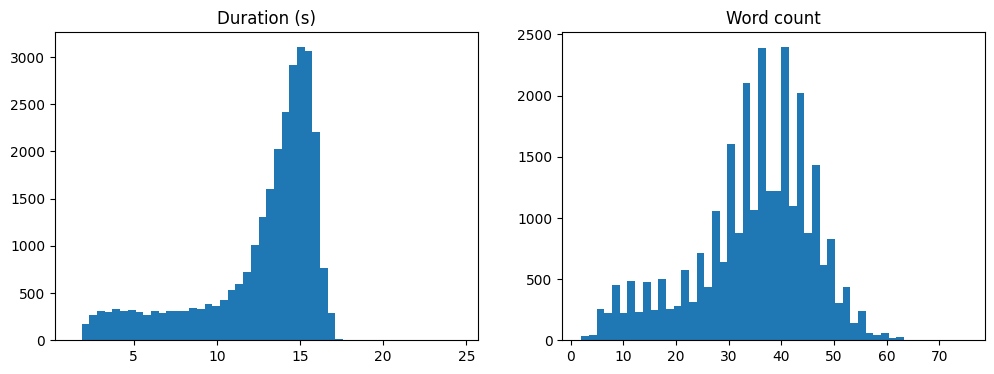

In [89]:
print(manifest_df["duration"].describe())
print(manifest_df["word_count"].describe())

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].hist(manifest_df["duration"], bins=50)
axes[0].set_title("Duration (s)")
axes[1].hist(manifest_df["word_count"], bins=50)
axes[1].set_title("Word count")
plt.show()

In [90]:
import numpy as np

sample_idx = manifest_df.sample(6, random_state=42).index
samples = manifest_df.loc[sample_idx]

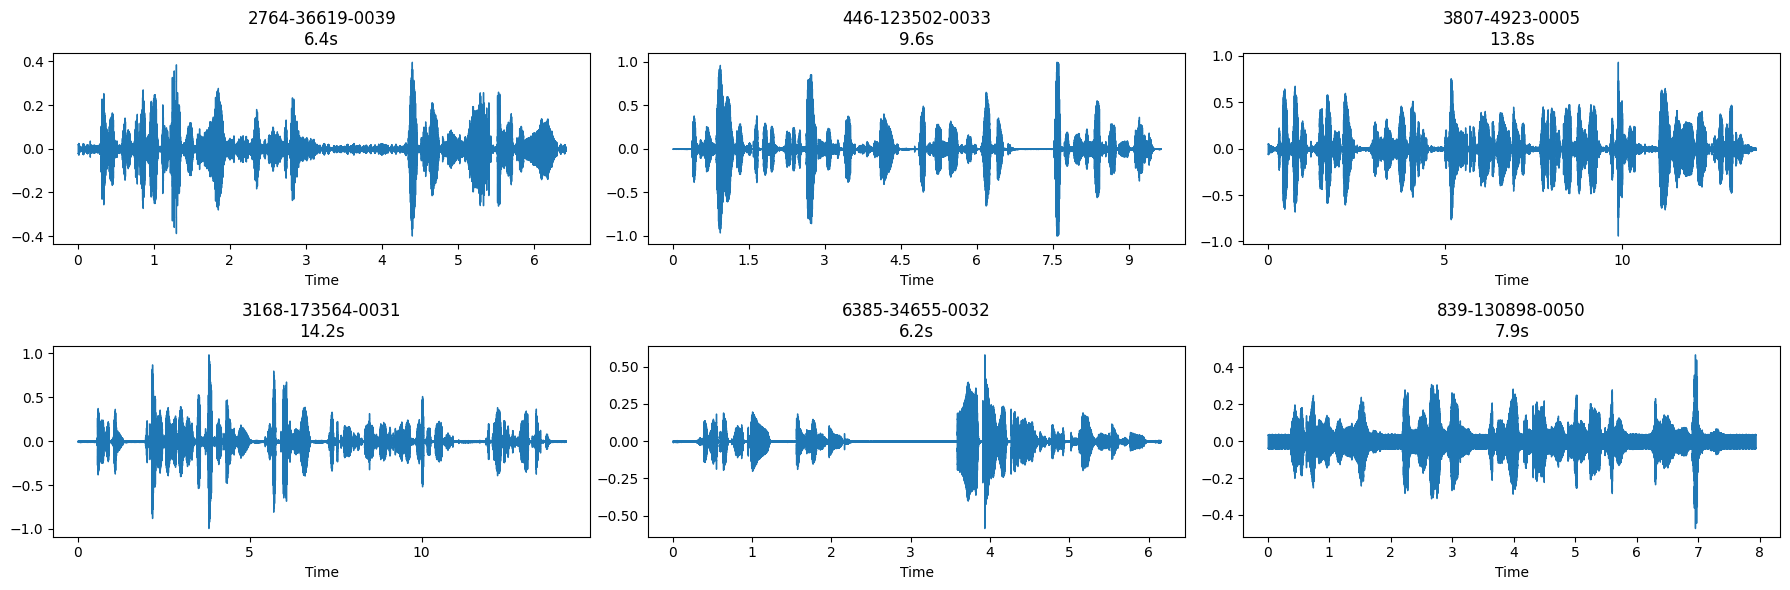

In [92]:
import librosa
import librosa.display
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(18, 6))
for ax, (_, row) in zip(axes.flatten(), samples.iterrows()):
    audio, sr = librosa.load(row["file"], sr=16000)
    librosa.display.waveshow(audio, sr=sr, ax=ax)
    ax.set_title(f"{row['id']}\n{row['duration']:.1f}s")
plt.tight_layout()
plt.show()

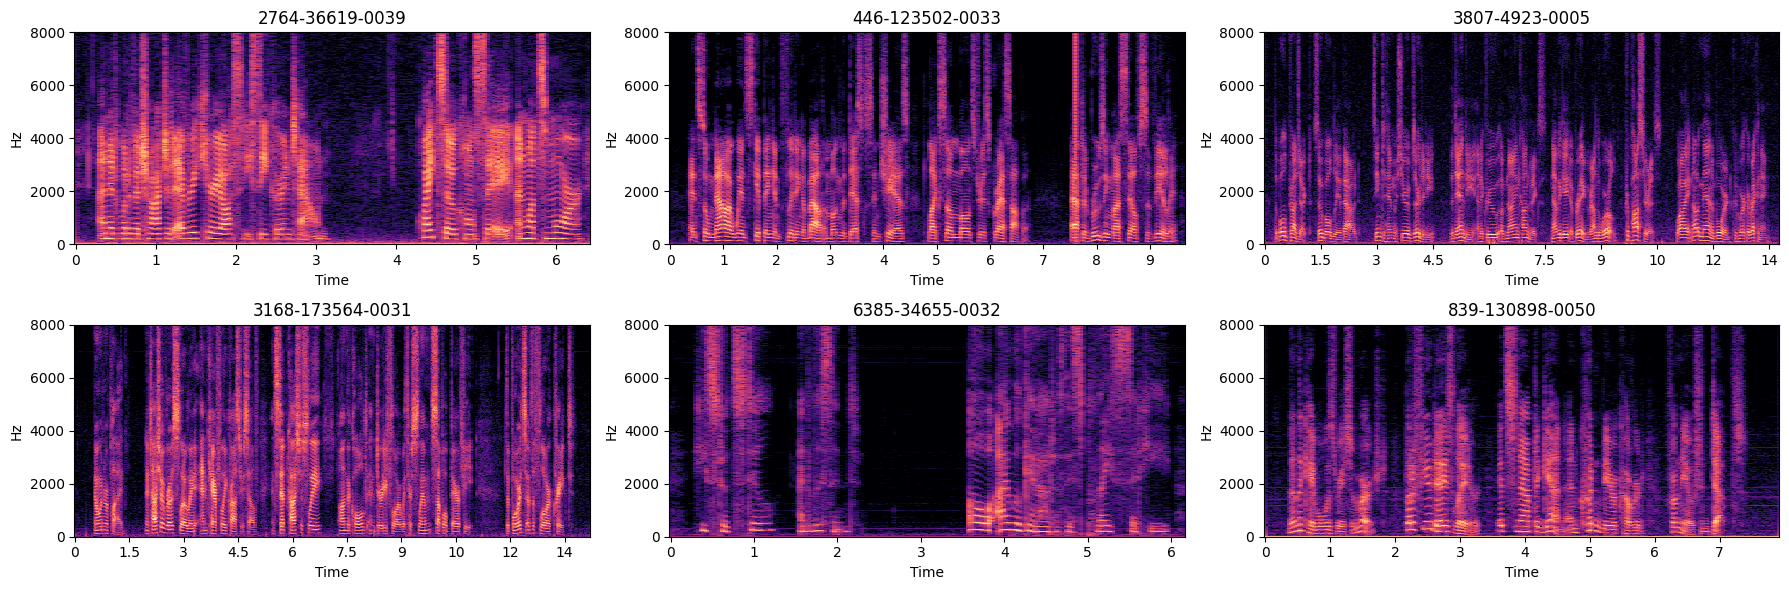

In [93]:
fig, axes = plt.subplots(2, 3, figsize=(18, 6))
for ax, (_, row) in zip(axes.flatten(), samples.iterrows()):
    audio, sr = librosa.load(row["file"], sr=16000)
    D = librosa.stft(audio)
    D_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    img = librosa.display.specshow(D_db, sr=sr, x_axis="time", y_axis="hz", ax=ax)
    ax.set_title(row["id"])
plt.tight_layout()
plt.show()

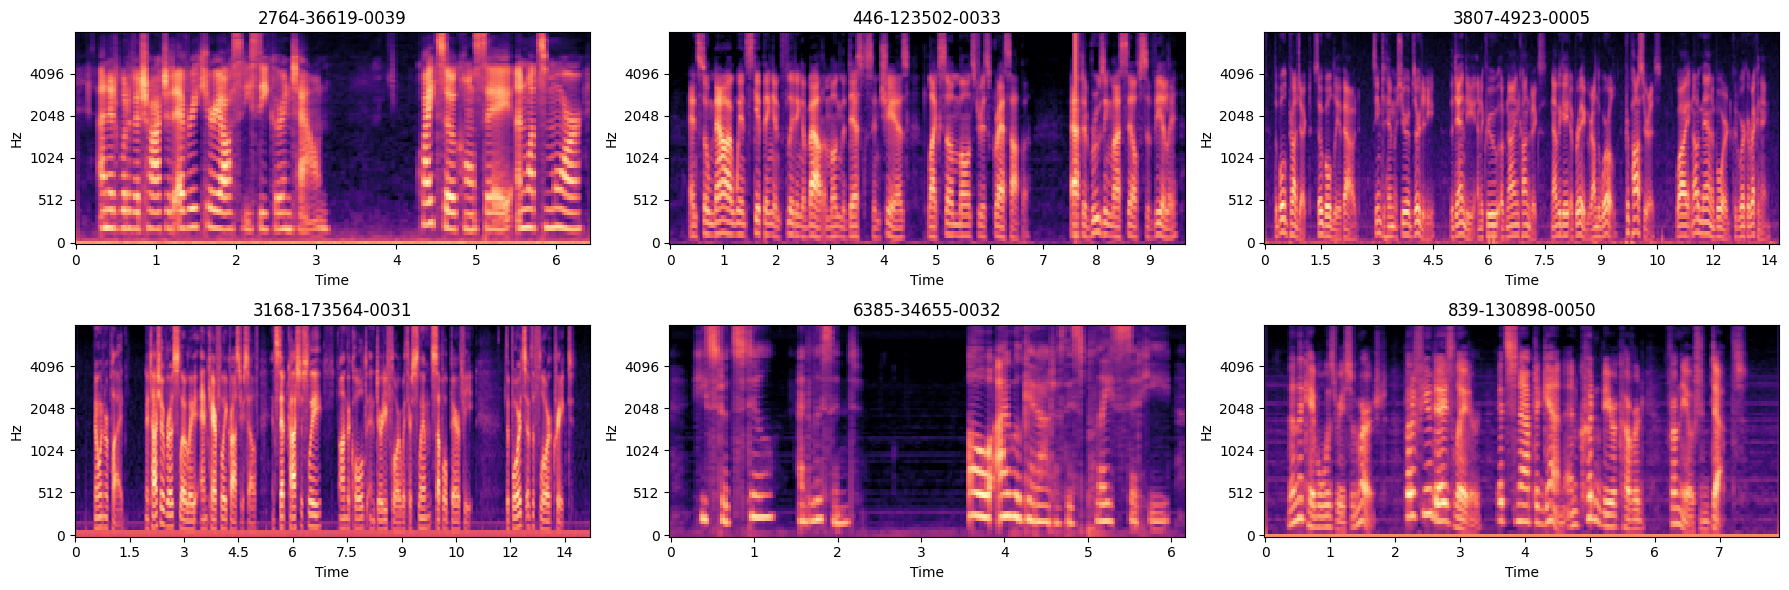

In [94]:
fig, axes = plt.subplots(2, 3, figsize=(18, 6))
for ax, (_, row) in zip(axes.flatten(), samples.iterrows()):
    audio, sr = librosa.load(row["file"], sr=16000)
    mel = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=80)
    mel_db = librosa.power_to_db(mel, ref=np.max)
    img = librosa.display.specshow(mel_db, sr=sr, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(row["id"])
plt.tight_layout()
plt.show()

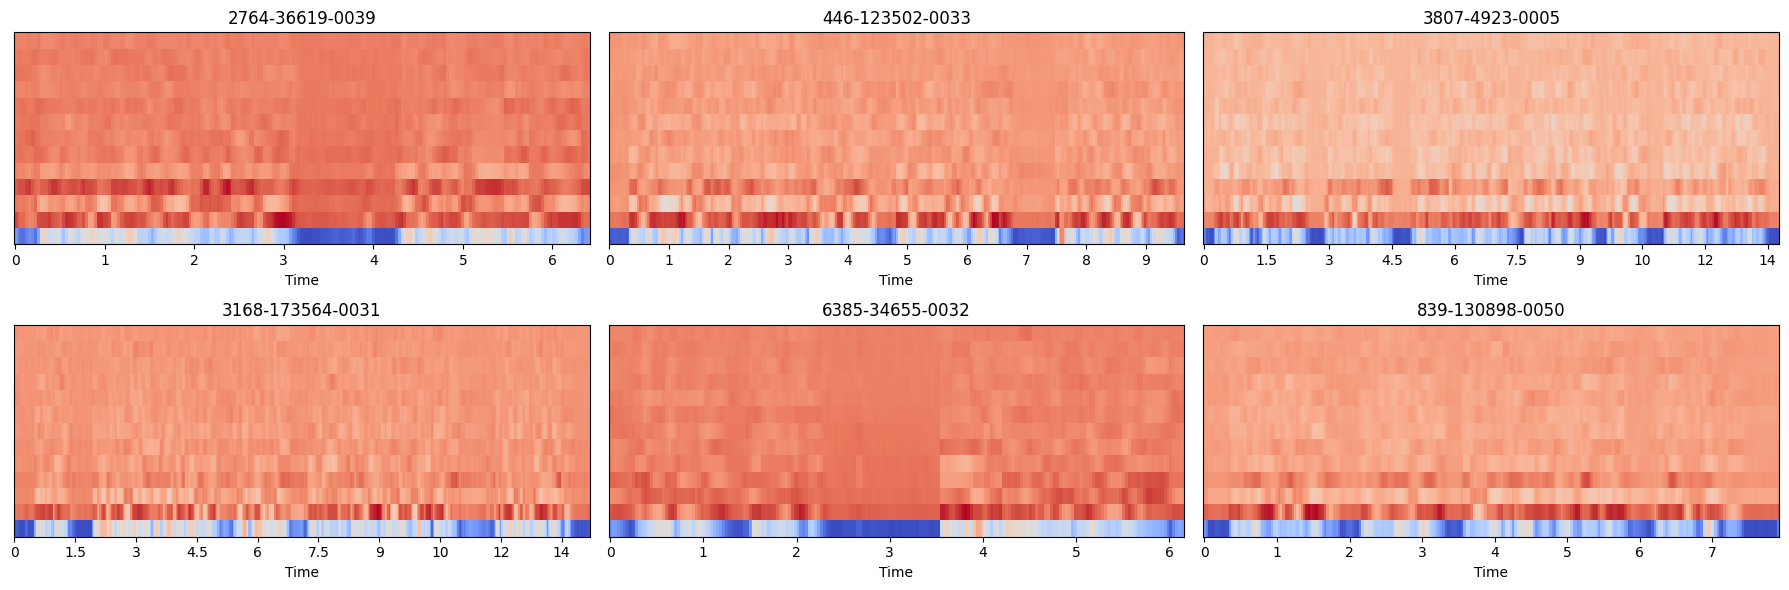

In [95]:
fig, axes = plt.subplots(2, 3, figsize=(18, 6))
for ax, (_, row) in zip(axes.flatten(), samples.iterrows()):
    audio, sr = librosa.load(row["file"], sr=16000)
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
    img = librosa.display.specshow(mfcc, sr=sr, x_axis="time", ax=ax)
    ax.set_title(row["id"])
plt.tight_layout()
plt.show()

In [96]:
def extract_features(path):
    audio, sr = librosa.load(path, sr=16000)
    return {
        "zcr": np.mean(librosa.feature.zero_crossing_rate(audio)),
        "rms_energy": np.mean(librosa.feature.rms(y=audio)),
        "spectral_centroid": np.mean(librosa.feature.spectral_centroid(y=audio, sr=sr)),
        "spectral_bandwidth": np.mean(librosa.feature.spectral_bandwidth(y=audio, sr=sr)),
        "spectral_rolloff": np.mean(librosa.feature.spectral_rolloff(y=audio, sr=sr)),
    }

# run on a sample subset (not all 28k — this decodes full audio, slow at scale)
feat_sample = manifest_df.sample(500, random_state=42)
feat_rows = feat_sample["file"].apply(extract_features)
feat_df = pd.DataFrame(list(feat_rows))
feat_df.head()

,zcr,rms_energy,spectral_centroid,spectral_bandwidth,spectral_rolloff
0,0.137690,0.026875,2156.358418,1678.982372,3892.024254
1,0.170286,0.046592,2118.884970,1524.633149,3742.834230
2,0.075788,0.074790,1457.643143,1506.823747,2974.351073
3,0.172141,0.038061,2293.961348,1723.794555,4068.940034
4,0.171007,0.029433,2344.615360,2049.735716,4668.474741


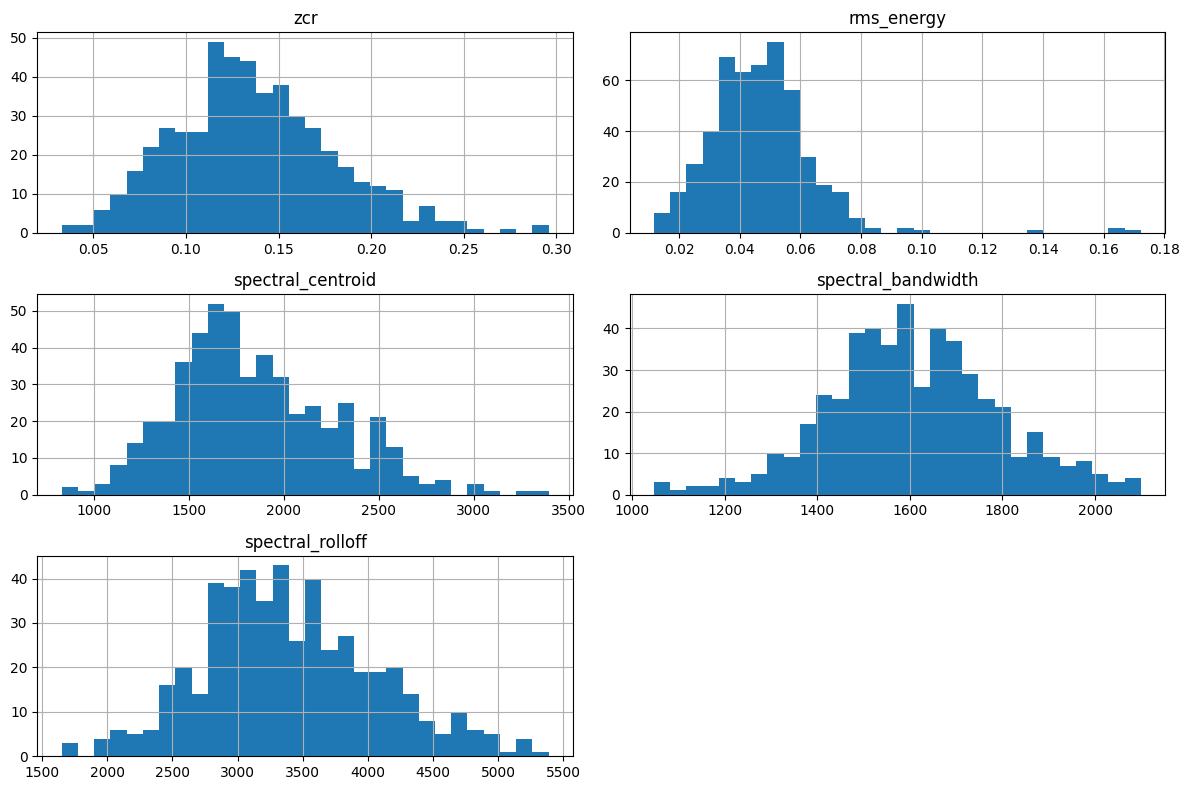

In [99]:
feat_df.hist(figsize=(12,8), bins=30)
plt.tight_layout()
plt.show()

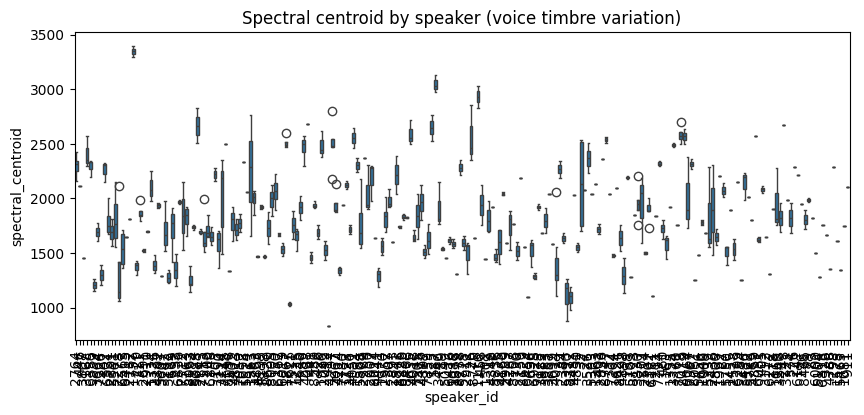

In [100]:
feat_sample_full = pd.concat([feat_sample.reset_index(drop=True), feat_df], axis=1)

import seaborn as sns
plt.figure(figsize=(10,4))
sns.boxplot(data=feat_sample_full, x="speaker_id", y="spectral_centroid")
plt.xticks(rotation=90)
plt.title("Spectral centroid by speaker (voice timbre variation)")
plt.show()

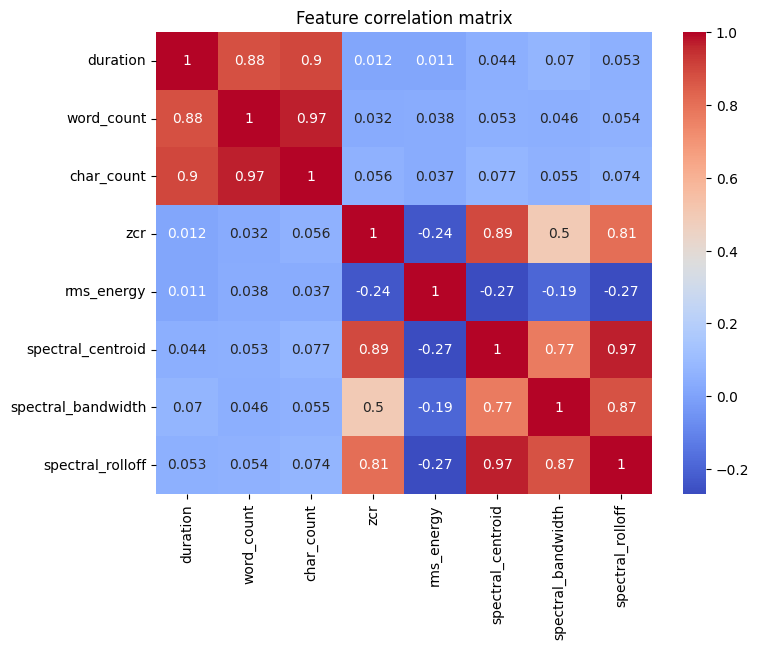

In [101]:
corr_df = pd.concat([feat_sample.reset_index(drop=True)[["duration","word_count","char_count"]], feat_df], axis=1)

plt.figure(figsize=(8,6))
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm")
plt.title("Feature correlation matrix")
plt.show()